# Beam splitter on VLQ and Sirius

Circuits from *Simulating bosonic interferences on a superconducting quantum computer* (sec. 4, 6).
Each mode is truncated to $|0\rangle..|3\rangle$ and encoded in 2 qubits: mode 1 = (q0, q1), mode 2 = (q2, q3), $n = 2\,q_\mathrm{msb} + q_\mathrm{lsb}$.

One general circuit with a symbolic $\theta$ is built and drawn, then evaluated at the chosen values `THETAS`.
Results are compared with the exact truncated unitary $\exp[\theta(\hat b_1^\dagger \hat b_2 - \hat b_1 \hat b_2^\dagger)]$;
for input $|1\rangle|1\rangle$ this is $P(2,0) = P(0,2) = \tfrac12 \sin^2 2\theta$, $P(1,1) = \cos^2 2\theta$ (HOM dip at $\theta = \pi/4$).

Circuits: `"full"` = whole $\hat U_{BS}(\theta, 0)$, any input; `"simplified"` = even sector only, input $|1\rangle|1\rangle$.
Backends: FakeVLQ (noisy Aer, VLQ calibration), real VLQ (LEXIS) and IQM Sirius (Resonance); each real device gets one job with all `THETAS`.
Qubits are picked from the calibration files in `calibration/VLQ/` and `calibration/SIRIUS/`.

In [1]:
import numpy as np

# ---- configuration ----
CIRCUIT  = "full"                # "full" (any input) or "simplified" (input |1>|1> only)
N1, N2   = 1, 1                  # input |N1>|N2>, each 0..3
THETAS   = [np.pi / 32 * n for n in range(17)]   # any values, e.g. [0.3] or np.linspace(0, np.pi / 2, 9)
SHOTS    = 4000
SEED     = 42
BACKENDS = ["FakeVLQ", "VLQ"]           # any of "FakeVLQ", "VLQ", "Sirius"
THETAS_PER_BACKEND = {"Sirius": [0, np.pi / 8, np.pi / 4]}  # fewer angles (credits); others run THETAS
LAYOUT   = {}                    # fixed qubits per backend, e.g. {"VLQ": ["QB13", "QB17", "QB9", "QB14"]}
SELECT_QUBITS = True             # backends not in LAYOUT: best qubits from calibration (False: transpiler's choice)
CALIBRATION = {"VLQ": "calibration/VLQ", "Sirius": "calibration/SIRIUS"}  # folder (newest file) or one file
SAVE     = True

In [2]:
# pick up edits in utils/*.py without restarting the kernel
%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from dotenv import load_dotenv
from qiskit.quantum_info import Statevector

from utils import qubit_select as qs
from utils import vlq
from utils.bs_circuits import bind, counts_to_fock, draw_ordered, exact_fock_probs, make_bs, postselect
from utils.metrics import SBhattC, tvd
from utils.results_io import make_run_dir, save_run

load_dotenv()
THETAS = [float(t) for t in THETAS]
thetas = {name: [float(t) for t in THETAS_PER_BACKEND.get(name, THETAS)] for name in BACKENDS}
TOTAL = N1 + N2
FOCK = [(a, b) for a in range(4) for b in range(4)]
SECTOR = [k for k in FOCK if sum(k) == TOTAL]  # outcomes allowed by photon-number conservation
results = {"config": {"circuit": CIRCUIT, "input": [N1, N2], "thetas": THETAS, "shots": SHOTS, "seed": SEED,
                      "backends": BACKENDS, "thetas_per_backend": thetas}}

## General circuit (symbolic $\theta$)

parameters: ParameterView([Parameter(θ)])


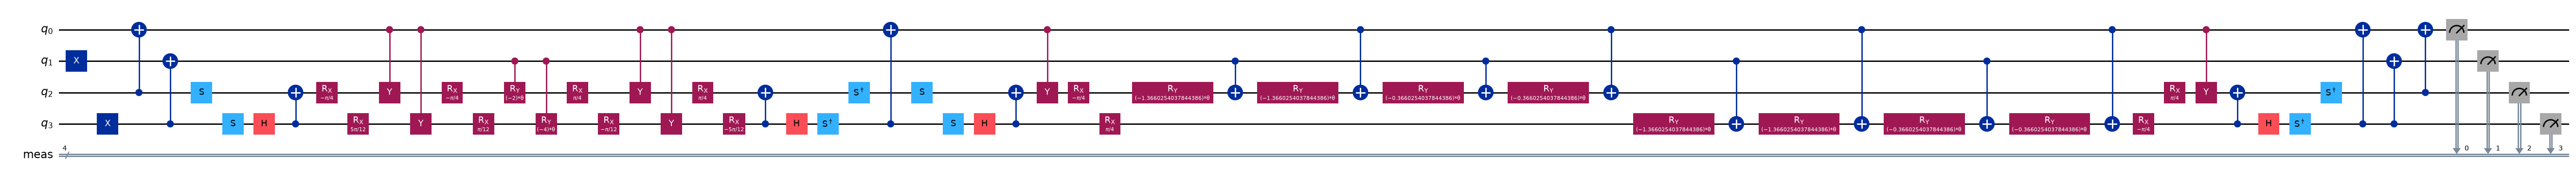

In [3]:
qc_general = make_bs(circuit=CIRCUIT, n1=N1, n2=N2)
print("parameters:", qc_general.parameters)
draw_ordered(qc_general)  # gates in PDF order; qc_general.draw('mpl') packs them

## Circuits at the chosen $\theta$ values (ideal check)

17 circuits match the exact unitary for input |1>|1>


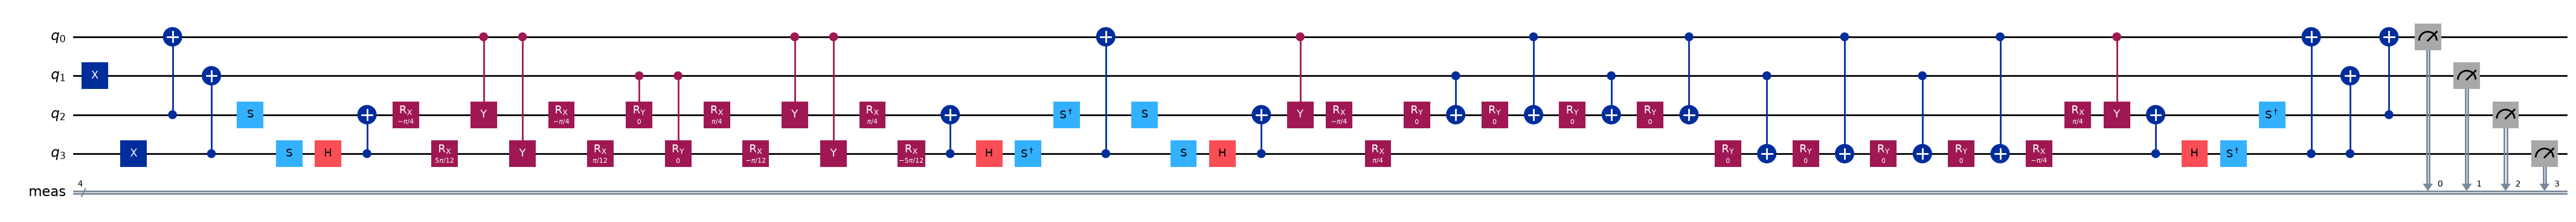

In [4]:
circuits = bind(qc_general, THETAS)
for t, qc in zip(THETAS, circuits):
    ideal = counts_to_fock(Statevector(qc.remove_final_measurements(inplace=False)).probabilities_dict())
    exact = exact_fock_probs(t, N1, N2)
    assert all(abs(ideal.get(k, 0) - exact.get(k, 0)) < 1e-9 for k in FOCK), t
print(f"{len(circuits)} circuits match the exact unitary for input |{N1}>|{N2}>")
draw_ordered(circuits[0])

## Backends and qubit selection
Per-qubit errors from the calibration file (readout, `prx`, CZ and MOVE with the resonator). The best few qubits are tried
in every order: each placement is transpiled and scored by its ESP (product of $1-\text{error}$ over all gates and
measurements; idling ignored). The same qubits are used for all `THETAS`. FakeVLQ uses its own calibration snapshot,
or VLQ's qubits when both run.

In [6]:
from utils.fake_vlq_backend import CALIBRATION_FILE as FAKE_CALIBRATION

ORDER = ["VLQ", "Sirius", "FakeVLQ"]
backends, layouts, selection = {}, dict(LAYOUT), {}
qc_ref = bind(qc_general, [np.pi / 8])[0]  # generic theta for scoring (theta = 0 lets the transpiler drop gates)
for name in sorted(BACKENDS, key=ORDER.index):
    backends[name] = vlq.get_backend(name)
    print(f"{name}: {backends[name].name}")
    if name == "FakeVLQ" and name not in layouts and "VLQ" in layouts:
        layouts[name] = layouts["VLQ"]
    if name in layouts or not SELECT_QUBITS:
        continue
    source = qs.CALIBRATION_DIR / "VLQ" / FAKE_CALIBRATION if name == "FakeVLQ" else CALIBRATION[name]
    obs, cal_id, cal_file = qs.load_calibration(source)
    print("  calibration:", cal_file)
    if name != "FakeVLQ":
        qs.check_calibration(backends[name], cal_id)
    errors = qs.qubit_errors(obs)
    qs.print_errors(errors, top=8)
    ranked = qs.best_layouts(qc_ref, backends[name], errors, seed=SEED)
    tr_default, default = vlq.transpile([qc_ref], backends[name], seed=SEED)
    for p, lay in ranked:
        print(f"  ESP {p:.3f}  {lay}")
    print(f"  ESP {qs.esp(tr_default[0], backends[name], errors):.3f}  {default}  (transpiler's own choice)")
    layouts[name] = ranked[0][1]
    selection[name] = {"calibration": cal_file, "calibration_set_id": cal_id, "ranked": ranked}
results["config"]["selection"] = selection

Welcome to the Py4LEXIS (v7.1.0)!
Proceeding login via login page...
Open provided url in your browser, please: https:/aai.lexis.tech/auth/realms/LEXIS_AAI_v2/protocol/openid-connect/auth/device?user_code=IEJH-PQHV
Check if user is logged in: Pending.                                            
Check if user is logged in: OK!
You have been successfully logged in LEXIS session.
VLQ: QBackendIQM
  calibration: 2026-11-09T04_57_57.687445Z.json
  calibration file matches the machine (29dd622d-d9f1-47dc-a14a-8d8492bcbc44)
qubit   readout      prx       cz     move   T1 us   T2 us    score
QB17     0.0141   0.0004   0.0045   0.0014    41.2    61.0   0.0218
QB13     0.0151   0.0006   0.0054   0.0014    36.0    19.0   0.0238
QB11     0.0148   0.0006   0.0078   0.0013    30.9    29.5   0.0257
QB14     0.0203   0.0009   0.0029   0.0012    45.7    37.7   0.0265
QB5      0.0155   0.0010   0.0073   0.0014    15.9    15.2   0.0267
QB16     0.0126   0.0007   0.0122   0.0016    40.6    32.1   0.0288
Q

## Run
All jobs are submitted first, then collected (real devices: one job each). A backend in `THETAS_PER_BACKEND` runs only its own angles.

In [7]:
transpiled, jobs = {}, {}
for name, backend in backends.items():
    circs = bind(qc_general, thetas[name])
    transpiled[name], layouts[name] = vlq.transpile(circs, backend, layout=layouts.get(name), seed=SEED)
    n2q = sum(v for k, v in transpiled[name][len(circs) // 2].count_ops().items() if k in ("cz", "move"))
    print(f"{name}: {len(circs)} thetas | layout {layouts[name]} | 2-qubit gates (mid theta) {n2q}")
    jobs[name] = vlq.submit(backend, transpiled[name], SHOTS, seed=SEED)
counts = {name: vlq.collect(job) for name, job in jobs.items()}

if "FakeVLQ" in backends:
    results["config"]["fake_calibration"] = FAKE_CALIBRATION
results["config"]["layouts"] = layouts
results["counts"] = counts

VLQ: 17 thetas | layout ['QB11', 'QB13', 'QB17', 'QB14'] | 2-qubit gates (mid theta) 69
QBackendIQM job id: 275
FakeVLQ: 17 thetas | layout ['QB11', 'QB13', 'QB17', 'QB14'] | 2-qubit gates (mid theta) 69


## Results
Raw: probability over all 16 outcomes. Post-selected: only $n_1 + n_2 = N_1 + N_2$ kept (photon number is conserved ideally), renormalised.

In [8]:
def analyse(counts_list, thetas_list):
    rows = []
    for t, c in zip(thetas_list, counts_list):
        p = counts_to_fock(c)
        ps, kept = postselect(p, TOTAL)
        ex = exact_fock_probs(t, N1, N2)
        rows.append({
            "raw": {str(k): p.get(k, 0.0) for k in FOCK},
            "post": {str(k): ps.get(k, 0.0) for k in SECTOR},
            "kept": kept,
            "SBC_raw": SBhattC([p.get(k, 0.0) for k in FOCK], [ex.get(k, 0.0) for k in FOCK]),
            "SBC_post": SBhattC([ps.get(k, 0.0) for k in SECTOR], [ex.get(k, 0.0) for k in SECTOR]),
            "TVD_post": tvd([ps.get(k, 0.0) for k in SECTOR], [ex.get(k, 0.0) for k in SECTOR]),
        })
    return rows

metrics = {name: analyse(c, thetas[name]) for name, c in counts.items()}
results["metrics"] = metrics

for name, rows in metrics.items():
    print(f"\n{name}\n theta   " + "  ".join(f"P{a}{b}" for a, b in SECTOR) + "  | kept   SBC_raw SBC_post")
    for t, r in zip(thetas[name], rows):
        print(f"{t:6.3f}  " + "  ".join(f"{r['raw'][str(k)]:.3f}" for k in SECTOR)
              + f"  | {r['kept']:.3f}  {r['SBC_raw']:.3f}   {r['SBC_post']:.3f}")


VLQ
 theta   P02  P11  P20  | kept   SBC_raw SBC_post
 0.000  0.010  0.018  0.015  | 0.043  0.018   0.422
 0.098  0.040  0.062  0.102  | 0.204  0.100   0.491
 0.196  0.043  0.046  0.101  | 0.190  0.115   0.608
 0.295  0.042  0.043  0.093  | 0.179  0.140   0.782
 0.393  0.038  0.032  0.101  | 0.170  0.146   0.858
 0.491  0.043  0.032  0.082  | 0.157  0.152   0.968
 0.589  0.043  0.035  0.094  | 0.172  0.165   0.964
 0.687  0.048  0.038  0.083  | 0.169  0.152   0.897
 0.785  0.061  0.060  0.060  | 0.182  0.121   0.668
 0.884  0.061  0.055  0.063  | 0.179  0.153   0.854
 0.982  0.059  0.054  0.065  | 0.178  0.171   0.964
 1.080  0.070  0.048  0.060  | 0.177  0.176   0.997
 1.178  0.082  0.041  0.050  | 0.173  0.159   0.917
 1.276  0.094  0.044  0.052  | 0.191  0.149   0.779
 1.374  0.103  0.034  0.045  | 0.182  0.099   0.543
 1.473  0.102  0.038  0.045  | 0.186  0.070   0.378
 1.571  0.071  0.056  0.071  | 0.198  0.056   0.283

FakeVLQ
 theta   P02  P11  P20  | kept   SBC_raw SBC_post
 0

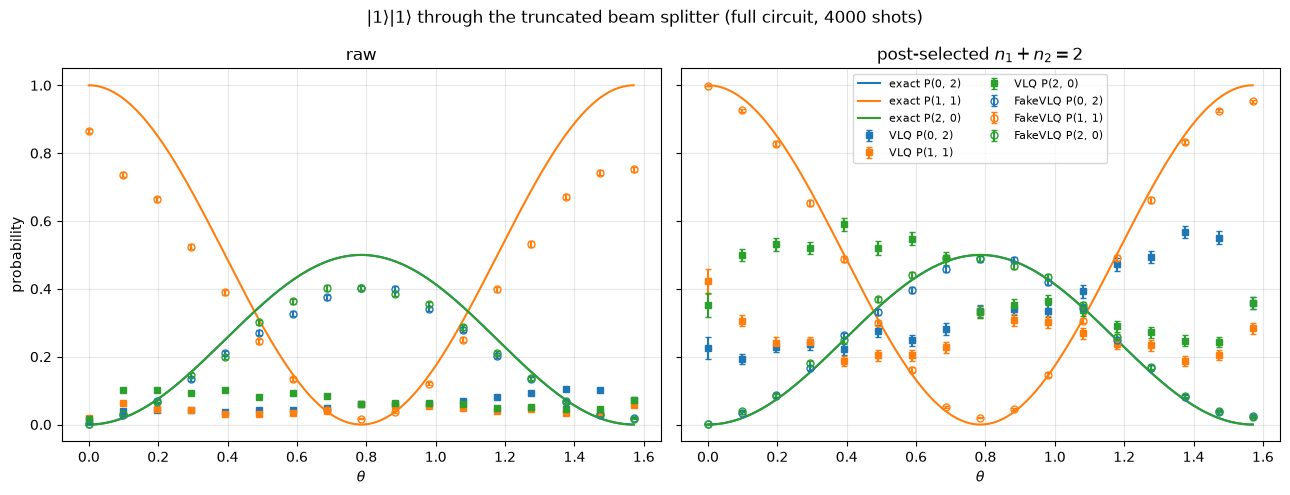

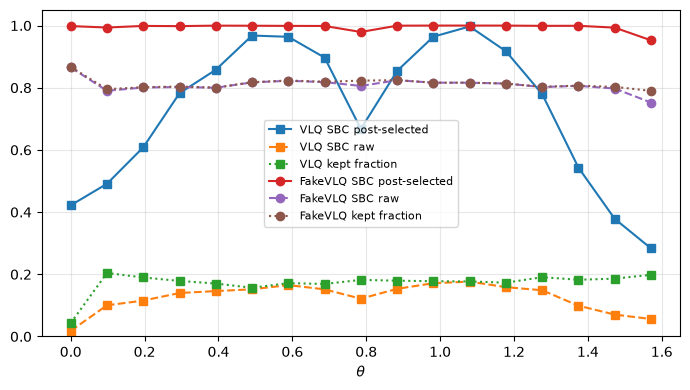

In [9]:
from fractions import Fraction
from matplotlib.lines import Line2D

RUN_DIR = make_run_dir(f"bs_{CIRCUIT}_in{N1}{N2}") if SAVE else None
markers = {"FakeVLQ": "o", "VLQ": "s", "Sirius": "^"}  # FakeVLQ hollow, hardware filled
colors = dict(zip(SECTOR, plt.get_cmap("tab10").colors))
styles = dict(zip(SECTOR, ["--", "-", ":", "-."]))  # dashed/solid so equal exact curves stay visible
title = rf"$|{N1}\rangle|{N2}\rangle$ through the truncated beam splitter ({CIRCUIT} circuit, {SHOTS} shots)"


def pi_ticks(ax):
    """x ticks at multiples of pi/8."""
    ticks = np.arange(0, max(THETAS) + 1e-9, np.pi / 8)
    if len(ticks) < 3:
        return
    labels = []
    for i in range(len(ticks)):
        f = Fraction(i, 8)
        labels.append("0" if i == 0 else f"{'' if f.numerator == 1 else f.numerator}π" + ("" if f.denominator == 1 else f"/{f.denominator}"))
    ax.set_xticks(ticks, labels)


def point_style(name, color):
    filled = name != "FakeVLQ"
    return dict(marker=markers[name], ls="none", ms=8, mew=1.5, color=color, mfc=color if filled else "white")


backend_legend = [Line2D([], [], **point_style(name, "0.3"), label=name) for name in metrics]

# probabilities vs theta (only with several theta values); lines = exact, points = measured
if len(THETAS) > 1:
    tt = np.linspace(min(THETAS), max(THETAS), 300)
    exact_tt = [exact_fock_probs(t, N1, N2) for t in tt]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
    for ax, kind in zip(axes, ["raw", "post"]):
        for k in SECTOR:
            ax.plot(tt, [e.get(k, 0.0) for e in exact_tt], color=colors[k], ls=styles[k], lw=2, alpha=0.6)
            for name, rows in metrics.items():
                ax.plot(thetas[name], [r[kind][str(k)] for r in rows], **point_style(name, colors[k]))
        ax.set_xlabel(r"$\theta$")
        ax.set_title("raw (all shots)" if kind == "raw" else rf"post-selected ($n_1+n_2={TOTAL}$ only)")
        ax.set_ylim(-0.02, 1.02)
        ax.grid(alpha=0.3)
        pi_ticks(ax)
    axes[0].set_ylabel("probability")
    outcome_legend = [Line2D([], [], color=colors[k], ls=styles[k], lw=2, label=f"exact P{k}") for k in SECTOR]
    fig.legend(handles=outcome_legend + backend_legend, loc="lower center", ncol=len(SECTOR) + len(metrics),
               frameon=False)
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0.07, 1, 1))
    if SAVE:
        plt.savefig(RUN_DIR / "probabilities_vs_theta.png", dpi=200)
    plt.show()

    # quality metrics vs theta: colour = metric, marker = backend
    metric_colors = {"kept": "tab:gray", "SBC_raw": "tab:blue", "SBC_post": "tab:red"}
    metric_labels = {"kept": "kept fraction", "SBC_raw": "SBC raw", "SBC_post": "SBC post-selected"}
    fig, ax = plt.subplots(figsize=(9, 5))
    for m, color in metric_colors.items():
        for name, rows in metrics.items():
            ax.plot(thetas[name], [r[m] for r in rows], **point_style(name, color))
            ax.plot(thetas[name], [r[m] for r in rows], color=color, lw=1, alpha=0.4)
    ax.set_xlabel(r"$\theta$")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    pi_ticks(ax)
    metric_legend = [Line2D([], [], color=c, lw=2, label=metric_labels[m]) for m, c in metric_colors.items()]
    fig.legend(handles=metric_legend + backend_legend, loc="lower center", ncol=3, frameon=False)
    ax.set_title(title, fontsize=10)
    plt.tight_layout(rect=(0, 0.12, 1, 1))
    if SAVE:
        plt.savefig(RUN_DIR / "metrics_vs_theta.png", dpi=200)
    plt.show()

In [ ]:
# all 16 outcomes per theta (bar charts) for at most 4 theta values that every backend ran
def theta_index(name, t):
    return next((i for i, s in enumerate(thetas[name]) if np.isclose(s, t)), None)

common = [t for t in THETAS if all(theta_index(name, t) is not None for name in metrics)][:4]
for t in common:
    exact = exact_fock_probs(t, N1, N2)
    bars = {"exact": [exact.get(k, 0.0) for k in FOCK]}
    bars |= {name: [rows[theta_index(name, t)]["raw"][str(k)] for k in FOCK] for name, rows in metrics.items()}
    x = np.arange(len(FOCK))
    w = 0.8 / len(bars)
    fig, ax = plt.subplots(figsize=(11, 3.5))
    for j, (name, vals) in enumerate(bars.items()):
        ax.bar(x + (j - (len(bars) - 1) / 2) * w, vals, w, label=name)
    ax.set_xticks(x, [f"{a}{b}" for a, b in FOCK])
    ax.set_xlabel(r"$n_1 n_2$")
    ax.set_ylabel("probability")
    ax.set_title(rf"$\theta = {t:.4f}$, " + title)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    if SAVE:
        plt.savefig(RUN_DIR / f"outcomes_theta{t:.4f}.png", dpi=200)
    plt.show()

In [ ]:
if SAVE:
    print("saved:", save_run(RUN_DIR, results))